In [27]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the cleaned TED Talks dataset
DATA_PATH = Path("../data/ted_talks_clean.csv")

df = pd.read_csv(DATA_PATH)

# Display dataset information
print("Dataset Shape:", df.shape)
print("\nDataset Columns:")
print(df.columns.tolist())

# Display first five records
display(df.head())

Dataset Shape: (2550, 17)

Dataset Columns:
['comments', 'description', 'duration', 'event', 'film_date', 'languages', 'main_speaker', 'name', 'num_speaker', 'published_date', 'ratings', 'related_talks', 'speaker_occupation', 'tags', 'title', 'url', 'views']


,comments,description,duration,event,film_date,languages,main_speaker,name,num_speaker,published_date,ratings,related_talks,speaker_occupation,tags,title,url,views
0,4553,Sir Ken Robinson makes an entertaining and pro...,1164,TED2006,1140825600,60,Ken Robinson,Ken Robinson: Do schools kill creativity?,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 19645}, {...","[{'id': 865, 'hero': 'https://pe.tedcdn.com/im...",Author/educator,"['children', 'creativity', 'culture', 'dance',...",Do schools kill creativity?,https://www.ted.com/talks/ken_robinson_says_sc...,47227110
1,265,With the same humor and humanity he exuded in ...,977,TED2006,1140825600,43,Al Gore,Al Gore: Averting the climate crisis,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 544}, {'i...","[{'id': 243, 'hero': 'https://pe.tedcdn.com/im...",Climate advocate,"['alternative energy', 'cars', 'climate change...",Averting the climate crisis,https://www.ted.com/talks/al_gore_on_averting_...,3200520
2,124,New York Times columnist David Pogue takes aim...,1286,TED2006,1140739200,26,David Pogue,David Pogue: Simplicity sells,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 964}, {'i...","[{'id': 1725, 'hero': 'https://pe.tedcdn.com/i...",Technology columnist,"['computers', 'entertainment', 'interface desi...",Simplicity sells,https://www.ted.com/talks/david_pogue_says_sim...,1636292
3,200,"In an emotionally charged talk, MacArthur-winn...",1116,TED2006,1140912000,35,Majora Carter,Majora Carter: Greening the ghetto,1,1151367060,"[{'id': 3, 'name': 'Courageous', 'count': 760}...","[{'id': 1041, 'hero': 'https://pe.tedcdn.com/i...",Activist for environmental justice,"['MacArthur grant', 'activism', 'business', 'c...",Greening the ghetto,https://www.ted.com/talks/majora_carter_s_tale...,1697550
4,593,You've never seen data presented like this. Wi...,1190,TED2006,1140566400,48,Hans Rosling,Hans Rosling: The best stats you've ever seen,1,1151440680,"[{'id': 9, 'name': 'Ingenious', 'count': 3202}...","[{'id': 2056, 'hero': 'https://pe.tedcdn.com/i...",Global health expert; data visionary,"['Africa', 'Asia', 'Google', 'demo', 'economic...",The best stats you've ever seen,https://www.ted.com/talks/hans_rosling_shows_t...,12005869


In [28]:
# Select important text columns
text_columns = ["title", "description", "tags"]

# Handle missing values
df[text_columns] = df[text_columns].fillna("")

# Combine title, description and tags
df["content"] = (
    df["title"].astype(str) + " " +
    df["description"].astype(str) + " " +
    df["tags"].astype(str)
).str.strip()

# Display the result
display(df[["title", "description", "tags", "content"]].head(5))

# Check empty content
print("Empty content rows:", df["content"].eq("").sum())

,title,description,tags,content
0,Do schools kill creativity?,Sir Ken Robinson makes an entertaining and pro...,"['children', 'creativity', 'culture', 'dance',...",Do schools kill creativity? Sir Ken Robinson m...
1,Averting the climate crisis,With the same humor and humanity he exuded in ...,"['alternative energy', 'cars', 'climate change...",Averting the climate crisis With the same humo...
2,Simplicity sells,New York Times columnist David Pogue takes aim...,"['computers', 'entertainment', 'interface desi...",Simplicity sells New York Times columnist Davi...
3,Greening the ghetto,"In an emotionally charged talk, MacArthur-winn...","['MacArthur grant', 'activism', 'business', 'c...",Greening the ghetto In an emotionally charged ...
4,The best stats you've ever seen,You've never seen data presented like this. Wi...,"['Africa', 'Asia', 'Google', 'demo', 'economic...",The best stats you've ever seen You've never s...


Empty content rows: 0


In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

# Convert text into numerical feature vectors
tfidf_matrix = tfidf.fit_transform(df["content"])

# Display matrix information
print("TF-IDF Matrix Shape:", tfidf_matrix.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))

TF-IDF Matrix Shape: (2550, 5000)
Number of features: 5000


In [30]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate similarity between all TED Talks
similarity_matrix = cosine_similarity(tfidf_matrix)

# Display matrix shape
print("Similarity Matrix Shape:", similarity_matrix.shape)

Similarity Matrix Shape: (2550, 2550)


In [31]:
def recommend_talks(talk_title, top_n=5):

    # Find the index of the selected TED Talk
    matches = df.index[
        df["title"].str.casefold() == talk_title.casefold()
    ].tolist()

    # Check whether the title exists
    if not matches:
        return f"Talk title not found: {talk_title}"

    idx = matches[0]

    # Get similarity scores for the selected talk
    scores = list(enumerate(similarity_matrix[idx]))

    # Sort talks by similarity score (highest first)
    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Remove the selected talk itself
    scores = [
        (i, score) for i, score in scores if i != idx
    ][:top_n]

    # Display recommended talks
    recommendations = df.loc[
        [i for i, score in scores],
        ["title", "main_speaker", "tags"]
    ].copy()

    recommendations["similarity"] = [
        round(score, 3) for i, score in scores
    ]

    return recommendations

In [32]:
recommend_talks("Do schools kill creativity?")

,title,main_speaker,tags,similarity
692,Bring on the learning revolution!,Ken Robinson,"['TED Brain Trust', 'children', 'creativity', ...",0.402
833,Changing education paradigms,Ken Robinson,"['TED Brain Trust', 'business', 'children', 'd...",0.298
1502,How to escape education's death valley,Ken Robinson,"['culture', 'education', 'student', 'teaching'...",0.288
760,The child-driven education,Sugata Mitra,"['children', 'education', 'global development'...",0.203
1550,The orchestra in my mouth,Tom Thum,"['TEDx', 'creativity', 'live music', 'music']",0.193


In [33]:
recommend_talks("Your body language may shape who you are")

,title,main_speaker,tags,similarity
1652,Don't kill your language,Suzanne Talhouk,"['TEDx', 'culture', 'language', 'poetry']",0.215
1388,A broken body isn't a broken person,Janine Shepherd,"['Human body', 'TEDx', 'body language', 'healt...",0.210
993,How language transformed humanity,Mark Pagel,"['biology', 'communication', 'culture', 'evolu...",0.192
1197,How can technology transform the human body?,Lucy McRae,"['Human body', 'TED Fellows', 'architecture', ...",0.186
2298,4 reasons to learn a new language,John McWhorter,"['communication', 'education', 'language', 'on...",0.166


In [34]:
recommend_talks("How great leaders inspire action")

,title,main_speaker,tags,similarity
555,Learning from leadership's missing manual,Fields Wicker-Miurin,"['environment', 'global issues', 'leadership',...",0.235
1682,What it takes to be a great leader,Roselinde Torres,"['business', 'leadership', 'motivation', 'wome...",0.214
1747,Why good leaders make you feel safe,Simon Sinek,"['business', 'leadership', 'military', 'work']",0.210
540,Lead like the great conductors,Itay Talgam,"['business', 'conducting', 'leadership', 'musi...",0.196
1140,Everyday leadership,Drew Dudley,"['TEDx', 'community', 'leadership', 'life', 'm...",0.194


In [35]:
import joblib
from pathlib import Path

# Create a folder to save the model files
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

# Save TF-IDF vectorizer
joblib.dump(tfidf, MODEL_DIR / "tfidf_vectorizer.pkl")

# Save similarity matrix
joblib.dump(similarity_matrix, MODEL_DIR / "similarity_matrix.pkl")

print("Model files saved successfully!")

Model files saved successfully!


In [36]:
import joblib

# Load saved model components
loaded_tfidf = joblib.load("../models/tfidf_vectorizer.pkl")
loaded_similarity = joblib.load("../models/similarity_matrix.pkl")

print("TF-IDF Vectorizer Loaded:", loaded_tfidf is not None)
print("Similarity Matrix Shape:", loaded_similarity.shape)

TF-IDF Vectorizer Loaded: True
Similarity Matrix Shape: (2550, 2550)


In [37]:
# Load transcript dataset
transcripts_df = pd.read_csv("../data/transcripts.csv")

# Remove duplicate transcript URLs
transcripts_df = transcripts_df.drop_duplicates(
    subset="url",
    keep="first"
)

# Merge transcripts with the main dataset
df = df.merge(
    transcripts_df[["url", "transcript"]],
    on="url",
    how="left"
)

# Handle missing transcripts
df["transcript"] = df["transcript"].fillna("")

# Check results
print("Dataset Shape:", df.shape)
print("Missing Transcripts:", (df["transcript"] == "").sum())

display(df[["title", "transcript"]].head())

Dataset Shape: (2550, 19)
Missing Transcripts: 86


,title,transcript
0,Do schools kill creativity?,Good morning. How are you?(Laughter)It's been ...
1,Averting the climate crisis,"Thank you so much, Chris. And it's truly a gre..."
2,Simplicity sells,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,Greening the ghetto,If you're here today — and I'm very happy that...
4,The best stats you've ever seen,"About 10 years ago, I took on the task to teac..."


In [38]:
# Handle missing values
text_columns = ["title", "description", "tags", "transcript"]

df[text_columns] = df[text_columns].fillna("")

# Combine all text features
df["full_content"] = (
    df["title"].astype(str) + " " +
    df["description"].astype(str) + " " +
    df["tags"].astype(str) + " " +
    df["transcript"].astype(str)
).str.strip()

# Check the combined content
display(
    df[["title", "full_content"]].head(3)
)

# Check empty content
print(
    "Empty content rows:",
    df["full_content"].eq("").sum()
)

,title,full_content
0,Do schools kill creativity?,Do schools kill creativity? Sir Ken Robinson m...
1,Averting the climate crisis,Averting the climate crisis With the same humo...
2,Simplicity sells,Simplicity sells New York Times columnist Davi...


Empty content rows: 0


In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer for full content
transcript_tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    max_df=0.95,
    min_df=2
)

# Convert combined text into numerical features
transcript_tfidf_matrix = transcript_tfidf.fit_transform(
    df["full_content"]
)

# Display results
print("TF-IDF Matrix Shape:", transcript_tfidf_matrix.shape)
print(
    "Number of Features:",
    len(transcript_tfidf.get_feature_names_out())
)

TF-IDF Matrix Shape: (2550, 10000)
Number of Features: 10000


In [40]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate similarity between TED Talks
transcript_similarity = cosine_similarity(
    transcript_tfidf_matrix
)

# Display matrix shape
print(
    "Transcript Similarity Matrix Shape:",
    transcript_similarity.shape
)

Transcript Similarity Matrix Shape: (2550, 2550)


In [41]:
def recommend_transcript_talks(talk_title, top_n=5):

    matches = df.index[
        df["title"].str.casefold() == talk_title.casefold()
    ].tolist()

    if not matches:
        return f"Talk title not found: {talk_title}"

    idx = matches[0]

    scores = list(enumerate(transcript_similarity[idx]))

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    scores = [
        (i, score) for i, score in scores if i != idx
    ][:top_n]

    recommendations = df.loc[
        [i for i, score in scores],
        ["title", "main_speaker", "tags"]
    ].copy()

    recommendations["similarity"] = [
        round(score, 3) for i, score in scores
    ]

    return recommendations

In [42]:
recommend_transcript_talks("Do schools kill creativity?")

,title,main_speaker,tags,similarity
692,Bring on the learning revolution!,Ken Robinson,"['TED Brain Trust', 'children', 'creativity', ...",0.412
1502,How to escape education's death valley,Ken Robinson,"['culture', 'education', 'student', 'teaching'...",0.409
21,Nerdcore comedy,Ze Frank,"['collaboration', 'comedy', 'community', 'cult...",0.333
1913,How to run a company with (almost) no rules,Ricardo Semler,"['business', 'creativity', 'leadership', 'phil...",0.306
568,A one-man world summit,Rory Bremner,"['comedy', 'global issues', 'government', 'hum...",0.303


In [43]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

# Save transcript-based vectorizer
joblib.dump(
    transcript_tfidf,
    MODEL_DIR / "transcript_tfidf_vectorizer.pkl"
)

# Save transcript-based TF-IDF matrix
joblib.dump(
    transcript_tfidf_matrix,
    MODEL_DIR / "transcript_tfidf_matrix.pkl"
)

# Save transcript-based similarity matrix
joblib.dump(
    transcript_similarity,
    MODEL_DIR / "transcript_similarity_matrix.pkl"
)

print("Transcript-based model files saved successfully!")

Transcript-based model files saved successfully!


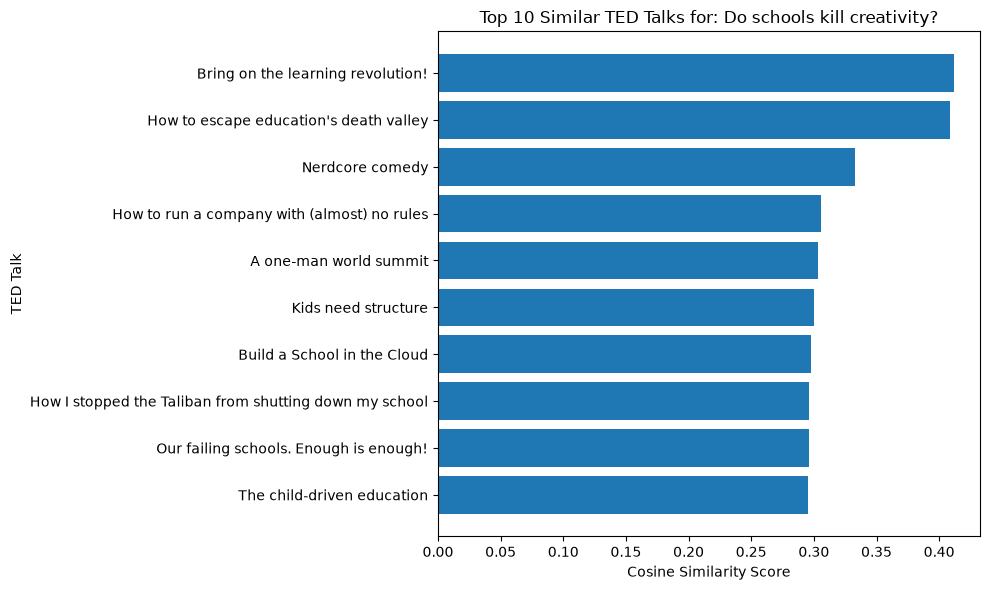

In [44]:
import matplotlib.pyplot as plt

talk_title = "Do schools kill creativity?"
recommendations = recommend_transcript_talks(talk_title, top_n=10)

if isinstance(recommendations, pd.DataFrame):
    plot_data = recommendations.sort_values(
        by="similarity",
        ascending=True
    )

    plt.figure(figsize=(10, 6))
    plt.barh(plot_data["title"], plot_data["similarity"])
    plt.xlabel("Cosine Similarity Score")
    plt.ylabel("TED Talk")
    plt.title(f"Top 10 Similar TED Talks for: {talk_title}")
    plt.tight_layout()
    plt.savefig(
    "../data/top_10_similar_talks.png",
    bbox_inches="tight",
    dpi=300
    )
    plt.show()

## Feature Engineering and Vectorization – Documentation

### 1. Text Data Preparation
The TED Talks dataset contains titles, descriptions, tags, and transcripts. These text fields were combined into a single `full_content` column to provide more information for content-based recommendations.

Missing transcript values were replaced with empty strings. The final dataset contains 2,550 TED Talks.

### 2. TF-IDF Vectorization
TF-IDF (Term Frequency–Inverse Document Frequency) was used to convert the text data into numerical feature vectors.

The following parameters were selected:

- `stop_words="english"`: Removes common English words.
- `max_features=10000`: Limits the vocabulary to 10,000 features.
- `ngram_range=(1, 2)`: Considers individual words and two-word phrases.
- `max_df=0.95`: Excludes terms appearing in more than 95% of documents.
- `min_df=2`: Excludes terms appearing in fewer than two documents.

The resulting TF-IDF matrix has 2,550 rows and 10,000 features.

### 3. Cosine Similarity
Cosine similarity was applied to calculate the similarity between TED Talks based on their TF-IDF vectors. A similarity matrix of shape 2,550 × 2,550 was generated.

### 4. Model Saving
The following trained components were saved using Joblib:

- TF-IDF vectorizer
- TF-IDF feature matrix
- Cosine similarity matrix

These saved files can be loaded later when building the recommendation application.

### 5. Similarity Score Visualization
A horizontal bar chart was created to visualize the top 10 TED Talks similar to "Do schools kill creativity?" The chart was saved as `top_10_similar_talks.png` in the data folder.

### 6. Collaborative Filtering Data Availability
The available dataset contains information such as talk views, comments, and ratings, but it does not provide individual user IDs or user-specific talk interactions. Therefore, a user-item interaction matrix cannot be constructed from the currently available data. This project currently focuses on content-based filtering.

In [45]:
# Save the dataset used by the transcript-based recommendation model

df.to_csv(
    "../data/ted_talks_with_transcripts.csv",
    index=False
)

print("Dataset saved successfully!")
print("Dataset shape:", df.shape)

Dataset saved successfully!
Dataset shape: (2550, 20)


## Recommendation Engine – Content-Based Filtering

### 1. Recommendation Approach
A content-based filtering approach was implemented to recommend TED Talks based on their textual content.

The model uses the title, description, tags, and transcript of each talk to identify similar talks.

### 2. Recommendation Process
1. Accept a TED Talk title as input.
2. Find the selected talk in the dataset.
3. Retrieve its cosine similarity scores against all other talks.
4. Sort the scores in descending order.
5. Exclude the selected talk itself.
6. Return the top 5 most similar TED Talks, including their titles, speakers, tags, and similarity scores.

### 3. Model Components
- TF-IDF vectorization for text feature extraction.
- Cosine similarity for measuring similarity between talks.
- A recommendation function to retrieve the most similar TED Talks.
- Joblib for saving the trained vectorizer and similarity matrices.

### 4. Future Development
The current implementation focuses on content-based filtering using TED Talk titles, descriptions, tags, and transcripts.

In a future development phase, additional user-interaction data will be collected to support collaborative filtering and explore a hybrid recommendation approach. This will help improve personalization by combining talk content with user preferences and interactions.

In [46]:
from sklearn.model_selection import train_test_split

# Split TED Talks into training and testing datasets
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

Training Dataset Shape: (2040, 20)
Testing Dataset Shape: (510, 20)


In [47]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create a new TF-IDF vectorizer
train_tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    max_df=0.95,
    min_df=2
)

# Learn vocabulary and transform training data
train_tfidf_matrix = train_tfidf.fit_transform(
    train_df["full_content"]
)

# Transform testing data using the same vectorizer
test_tfidf_matrix = train_tfidf.transform(
    test_df["full_content"]
)

print("Training TF-IDF Shape:", train_tfidf_matrix.shape)
print("Testing TF-IDF Shape:", test_tfidf_matrix.shape)

Training TF-IDF Shape: (2040, 10000)
Testing TF-IDF Shape: (510, 10000)


In [48]:
from sklearn.metrics.pairwise import cosine_similarity

# Compare testing talks with training talks
test_train_similarity = cosine_similarity(
    test_tfidf_matrix,
    train_tfidf_matrix
)

print("Test-Train Similarity Shape:", test_train_similarity.shape)

Test-Train Similarity Shape: (510, 2040)


In [49]:
def recommend_from_test_set(test_index, top_n=5):

    # Get similarity scores for the selected testing talk
    scores = test_train_similarity[test_index]

    # Get indices of the top similar training talks
    top_indices = np.argsort(scores)[::-1][:top_n]

    # Retrieve recommended talks
    recommendations = train_df.iloc[top_indices][
        ["title", "main_speaker", "tags"]
    ].copy()

    # Add similarity scores
    recommendations["similarity"] = [
        round(scores[i], 3) for i in top_indices
    ]

    return recommendations

In [50]:
# Select the first testing TED Talk
selected_talk = test_df.iloc[0]["title"]

print("Selected TED Talk:", selected_talk)
print("\nRecommended TED Talks:")

display(recommend_from_test_set(0, top_n=5))

Selected TED Talk: How the "ghost map" helped end a killer disease

Recommended TED Talks:


,title,main_speaker,tags,similarity
2335,Maps that show us who we are (not just where w...,Danny Dorling,"['TEDx', 'data', 'economics', 'global developm...",0.275
533,New York -- before the City,Eric Sanderson,"['cities', 'environment', 'history', 'life', '...",0.216
1426,A country with no water,Fahad Al-Attiya,"['Middle East', 'TEDx', 'agriculture', 'cities...",0.207
1344,Making sense of maps,Aris Venetikidis,"['TEDx', 'brain', 'design', 'interface design'...",0.197
2113,4 ways we can avoid a catastrophic drought,David Sedlak,"['TEDx', 'chemistry', 'climate change', 'desig...",0.192


In [51]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

# Save train-test recommendation model components
joblib.dump(train_tfidf, MODEL_DIR / "train_test_tfidf_vectorizer.pkl")
joblib.dump(train_tfidf_matrix, MODEL_DIR / "train_tfidf_matrix.pkl")
joblib.dump(test_tfidf_matrix, MODEL_DIR / "test_tfidf_matrix.pkl")
joblib.dump(test_train_similarity, MODEL_DIR / "test_train_similarity.pkl")

# Save training and testing datasets
joblib.dump(train_df, MODEL_DIR / "train_dataset.pkl")
joblib.dump(test_df, MODEL_DIR / "test_dataset.pkl")

print("Train-test recommendation model saved successfully!")

Train-test recommendation model saved successfully!


## Model Training and Hyperparameter Documentation

### 1. Recommendation Model
A content-based recommendation model was developed using TF-IDF vectorization and cosine similarity.

### 2. Dataset Splitting
The dataset containing 2,550 TED Talks was divided into:
- Training dataset: 2,040 talks (80%)
- Testing dataset: 510 talks (20%)

The split was performed using `train_test_split()` with `random_state=42` to ensure reproducibility.

### 3. TF-IDF Hyperparameters

The following parameters were used:

| Parameter | Value |
|---|---|
| stop_words | english |
| max_features | 10000 |
| ngram_range | (1, 2) |
| max_df | 0.95 |
| min_df | 2 |

The vectorizer was fitted on the training dataset and used to transform the testing dataset.

### 4. Similarity Calculation
Cosine similarity was calculated between the testing and training TF-IDF matrices, producing a similarity matrix of shape (510, 2040).

### 5. Recommendation Process
A recommendation function was developed to retrieve the top 5 most similar training TED Talks for a selected testing talk. Recommendations include the talk title, speaker, tags, and similarity score.

### 6. Model Saving
The following components were saved using Joblib:
- Training TF-IDF vectorizer
- Training TF-IDF matrix
- Testing TF-IDF matrix
- Test-training similarity matrix
- Training dataset
- Testing dataset

### 7. Future Development
The current system uses content-based filtering. Additional user-interaction data may be collected in a future phase to explore collaborative filtering and hybrid recommendations.